Transformers:-

GPT: Generative Pretrained Transformer

Transformer Architecture
- Attention is All You Need : Paper behind GPT proposing a new model architecture called the Transformers
- Before Transformers, we used the LSTM models (Long short term memory) which was type of recurrent neural network

Number of parameters in models (log scale)
GPT-1: 117M
GPT-2: 1.5B
GPT-3: 175B
GPT-4: 1.76T


Introducing Tokens

- In early days neural networks were trained at the character level - Predict the next character in this sequence
- Then neural networks were trained off words - Predict the next word in this sequence
- Then breakthrough was to work with chunks of words, called 'tokens' - Handles word stems 


OpenAI's large language models process text using tokens, which are common sequences of characters found in a set of text. The models learn to understand the statistical relationships between these tokens, and excel at producing the next token in a sequence of tokens.

Text generation and embeddings models process text in chunks called tokens. Tokens represent commonly occurring sequences of characters. For example, the string “ tokenization” is decomposed as “ token” and “ization”, while a short and common word like “ the” is represented as a single token. Note that in a sentence, the first token of each word typically starts with a space character. Check out our tokenizer tool to test specific strings and see how they are translated into tokens. As a rough rule of thumb, 1 token is approximately 4 characters or 0.75 words for English text.

Tokenizer in openai platform 
Text: "An important sentence for my class of AI engineers"
Tokens: 9 | Characters: 50

Text: "An exquisitively handcrafted quip for my masterers of LLM witchcraft"
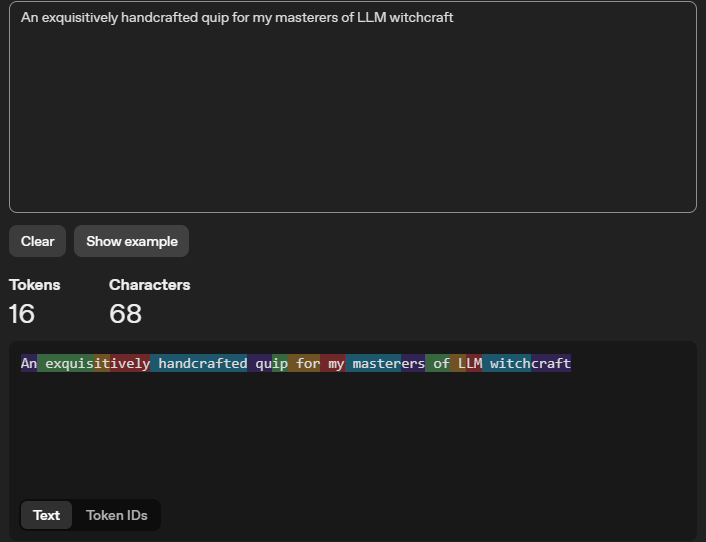

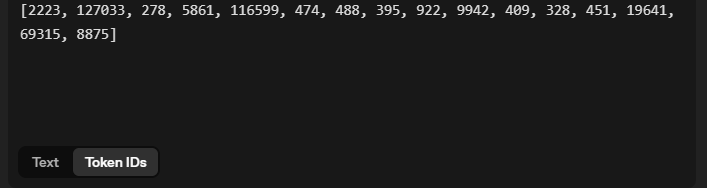

Observations:
- Less common words (and invented words!) get broken into multiple tokens
- In many cases, the meaning is still captured by the tokens: hand_crafted, master_ers
- Sometimes, like qu_ip, the word is broken into fragments

In earlier versions of GPT, the numbers or digits were treated separately - because any math with more than 4 digits - it split that number into 2 parts - one with 3 digit and other with one digit

### Rule of Thumb
- 1 token is ~4 characters
- 1 token is ~0.75 words
- So 1000 tokens is ~750 words
- As you move to scientific or math problems - tokens will be higher because of the symbols and characters (can be obscure to understand)

In [27]:
import tiktoken

encoding = tiktoken.encoding_for_model("gpt-4.1-mini")
for text in ["My name is Joel", "My name is joel", "My name is Elephant", "My name is elephant"]:
    tokens = encoding.encode(text)
    for token_id in tokens:
        token_text = encoding.decode([token_id])
        print(f"Token ID: {token_id} | Token: {token_text}")
    print("\n\n")

Token ID: 5444 | Token: My
Token ID: 1308 | Token:  name
Token ID: 382 | Token:  is
Token ID: 62230 | Token:  Joel



Token ID: 5444 | Token: My
Token ID: 1308 | Token:  name
Token ID: 382 | Token:  is
Token ID: 8483 | Token:  jo
Token ID: 296 | Token: el



Token ID: 5444 | Token: My
Token ID: 1308 | Token:  name
Token ID: 382 | Token:  is
Token ID: 123231 | Token:  Elephant



Token ID: 5444 | Token: My
Token ID: 1308 | Token:  name
Token ID: 382 | Token:  is
Token ID: 84859 | Token:  elephant





Observations:
- Here the token id for the same word is not changing
- Lowercase names and Titlecase names are treated differently - Lowercase names are one token whereas as titlecase names are split
- Pretrained words as kept as is like elephant in both cases

Notes
- Every call you make to LLM is stateless means every call is fresh, to retain the memory you need pass in the previous conversations/context everytime.
- Also as conversations grow, make sure to either combine it or summarize it (to compress or reduce the input context) and send it everytime

In [ ]:
# Example

import openai

messages = [
    {"role": "system", "content": "You are a helpful assistant"},
    {"role": "user", "content": "Hi! I'm Ed!"},
    {"role": "assistant", "content": "Hi Ed! How can I assist you today?"},  # Response back from LLM
    {"role": "user", "content": "What's my name?"}
]

response = openai.chat.completions.create(model="gpt-4.1-mini", messages=messages)
response.choices[0].message.content

'Your name is Ed! How can I help you today, Ed?'

## To recap

With apologies if this is obvious to you - but it's still good to reinforce:

1. Every call to an LLM is stateless
2. We pass in the entire conversation so far in the input prompt, every time
3. This gives the illusion that the LLM has memory - it apparently keeps the context of the conversation
4. But this is a trick; it's a by-product of providing the entire conversation, every time
5. An LLM just predicts the most likely next tokens in the sequence; if that sequence contains "My name is Ed" and later "What's my name?" then it will predict.. Ed!

The ChatGPT product uses exactly this trick - every time you send a message, it's the entire conversation that gets passed in.

"Does that mean we have to pay extra each time for all the conversation so far"

For sure it does. And that's what we WANT. We want the LLM to predict the next tokens in the sequence, looking back on the entire conversation. We want that compute to happen, so we need to pay the electricity bill for it!



Context Window - Is maximum number of tokens that the model can consider when generating the next token (Input, Output, Previous Conversation If there)

Important for mult-shot prompting where the prompt includes examples, or for long conversations
